<a href="https://colab.research.google.com/github/SurajBhosale97/E22CSEU1743_lab5/blob/main/AQI_DELHI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kagglehub

import kagglehub

path = kagglehub.dataset_download(
    "rohanrao/air-quality-data-in-india"
)

print("Dataset location:", path)

Using Colab cache for faster access to the 'air-quality-data-in-india' dataset.
Dataset location: /kaggle/input/air-quality-data-in-india


LOAD ONLY DELHI DATA

Date
2015-01-01    472.0
2015-01-02    454.0
2015-01-03    143.0
2015-01-04    319.0
2015-01-05    325.0
Freq: D, Name: AQI, dtype: float64
Missing readings: 10


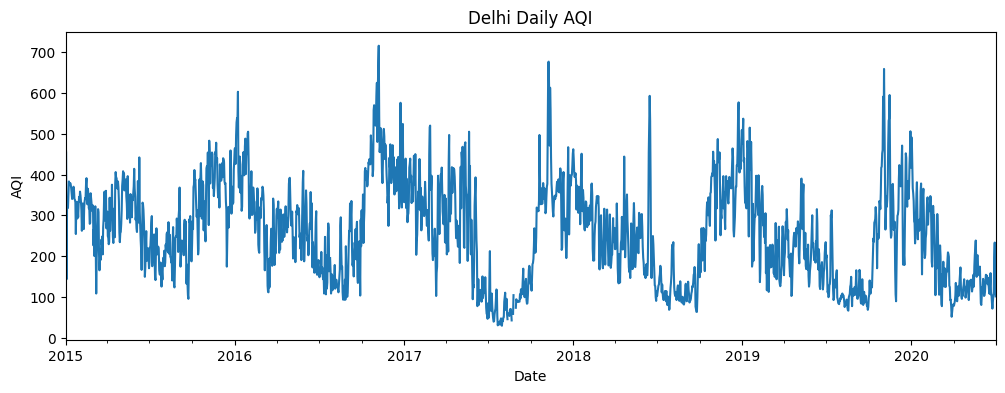

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_path = next(Path(path).rglob("city_day.csv"))
df = pd.read_csv(csv_path)

delhi = df.loc[df["City"] == "Delhi", ["Date", "AQI"]].copy()
delhi["Date"] = pd.to_datetime(delhi["Date"])

# Create a daily time series
aqi = (
    delhi.groupby("Date")["AQI"]
    .mean()
    .sort_index()
    .asfreq("D")
)

# Start from the first available AQI reading
aqi = aqi.loc[aqi.first_valid_index():]

print(aqi.head())
print("Missing readings:", aqi.isna().sum())

aqi.plot(figsize=(12, 4), title="Delhi Daily AQI")
plt.ylabel("AQI")
plt.show()

2. Split past and future data

In [ ]:
# Last 30 days are used to test predictions
train = aqi.iloc[:-30].ffill()
test = aqi.iloc[-30:]

print("Training days:", len(train))
print("Testing days:", len(test))

Training days: 1979
Testing days: 30


3. Train ARIMA and SARIMA

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ARIMA
arima = ARIMA(train, order=(1, 1, 1)).fit()
arima_pred = arima.forecast(steps=len(test))

# SARIMA: try a weekly seasonal pattern
sarima = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7)
).fit(disp=False)

sarima_pred = sarima.forecast(steps=len(test))

4. Compare prediction accuracy

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline: predict the last training AQI for every test day
baseline_pred = pd.Series(train.iloc[-1], index=test.index)

# Evaluate only days with actual AQI readings
valid = test.notna()

predictions = {
    "Baseline": baseline_pred,
    "ARIMA": arima_pred,
    "SARIMA": sarima_pred
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(test[valid], pred[valid]),
        "RMSE": np.sqrt(
            mean_squared_error(test[valid], pred[valid])
        )
    })

results = pd.DataFrame(results).set_index("Model")
print(results.round(2))

            MAE   RMSE
Model                 
Baseline  29.63  41.06
ARIMA     24.99  32.77
SARIMA    24.90  32.76


5. Plot actual versus predicted AQI

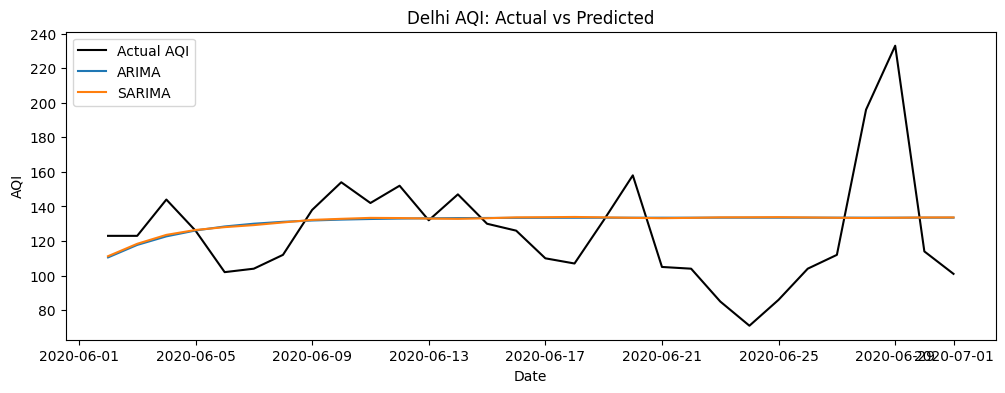

In [ ]:
plt.figure(figsize=(12, 4))

plt.plot(test.index, test, label="Actual AQI", color="black")
plt.plot(test.index, arima_pred, label="ARIMA")
plt.plot(test.index, sarima_pred, label="SARIMA")

plt.title("Delhi AQI: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.show()

6. Forecast the next 7 days using the better forecasting model

Selected model: SARIMA

7-day forecast:
2020-07-02    107.61
2020-07-03    112.79
2020-07-04    115.96
2020-07-05    119.68
2020-07-06    122.12
2020-07-07    119.44
2020-07-08    119.38
Freq: D, Name: predicted_mean, dtype: float64


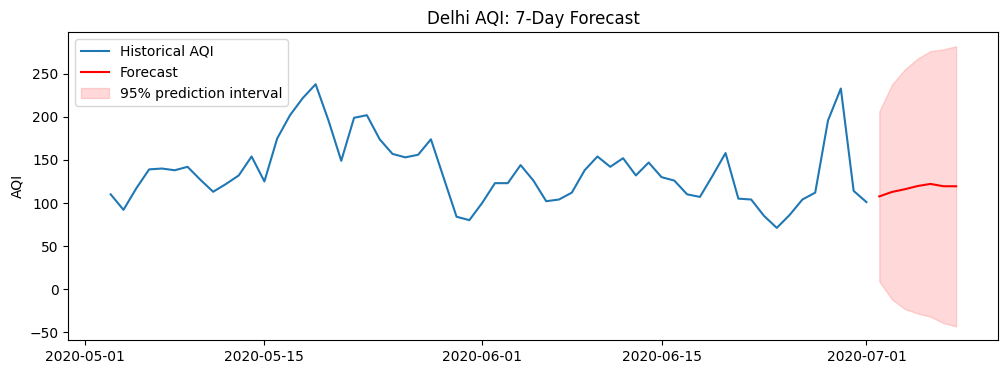

In [ ]:
best_model = results.loc[["ARIMA", "SARIMA"], "RMSE"].idxmin()
full_data = aqi.ffill()

if best_model == "ARIMA":
    final_model = ARIMA(full_data, order=(1, 1, 1)).fit()
else:
    final_model = SARIMAX(
        full_data,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 7)
    ).fit(disp=False)

forecast = final_model.get_forecast(steps=7)
future = forecast.predicted_mean
interval = forecast.conf_int()

print("Selected model:", best_model)
print("\n7-day forecast:")
print(future.round(2))

plt.figure(figsize=(12, 4))
plt.plot(full_data.tail(60), label="Historical AQI")
plt.plot(future, label="Forecast", color="red")
plt.fill_between(
    future.index,
    interval.iloc[:, 0],
    interval.iloc[:, 1],
    color="red",
    alpha=0.15,
    label="95% prediction interval"
)
plt.title("Delhi AQI: 7-Day Forecast")
plt.ylabel("AQI")
plt.legend()
plt.show()

In [ ]:
print(df.columns.tolist())

['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


These six graphs show how pollutant concentrations changed over time. Each graph has its own scale, so compare trends rather than line heights across graphs. Missing months remain gaps.

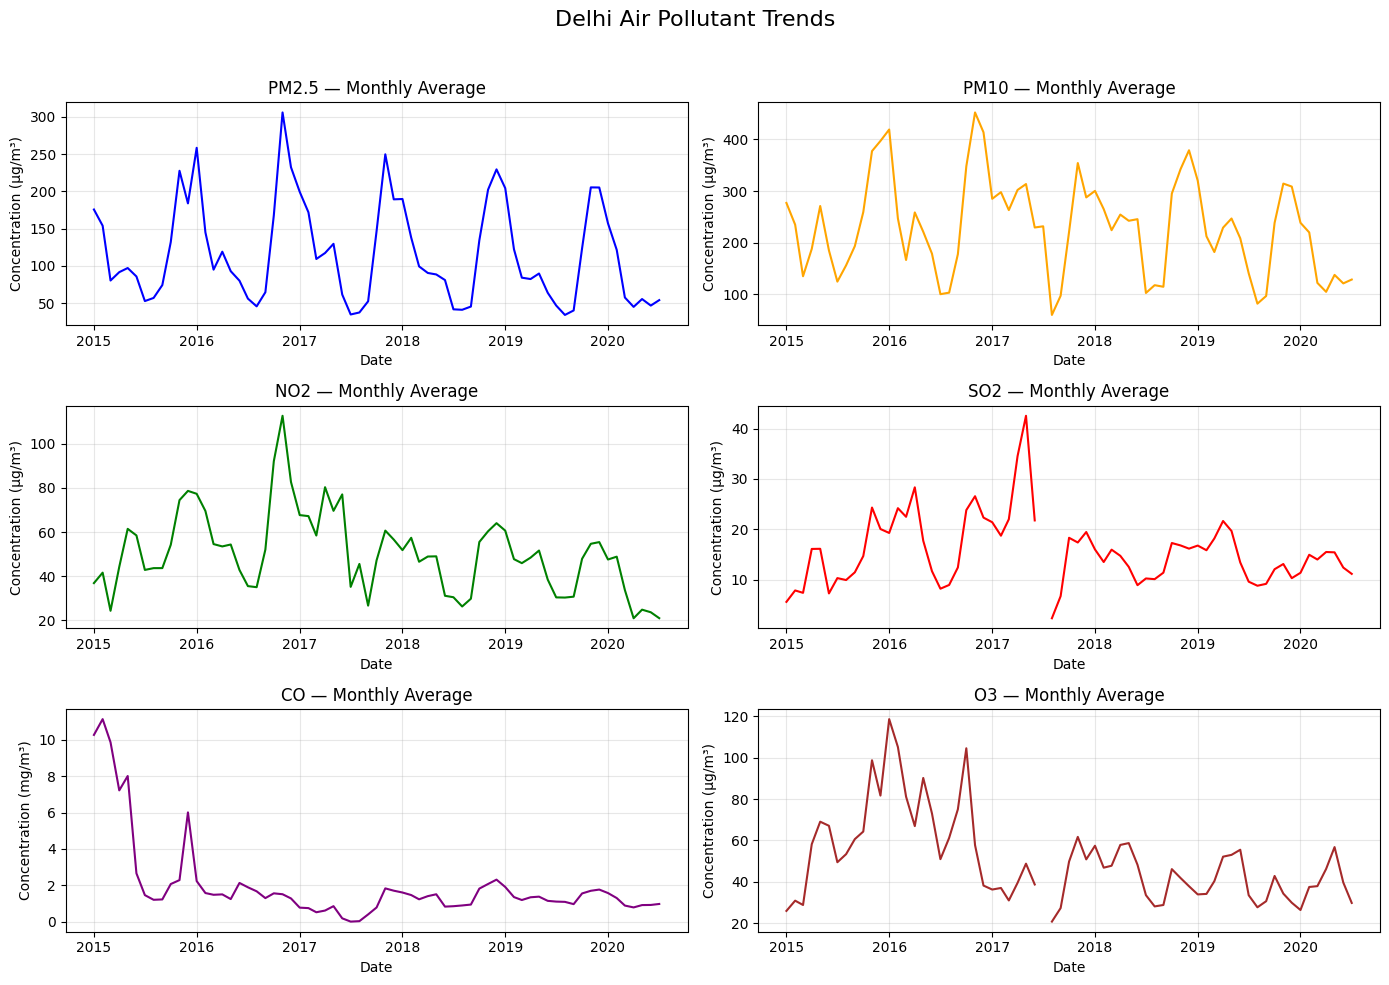

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Keep all pollutant columns for Delhi
delhi_pollutants = df[df["City"] == "Delhi"].copy()
delhi_pollutants["Date"] = pd.to_datetime(delhi_pollutants["Date"])
delhi_pollutants = delhi_pollutants.set_index("Date").sort_index()

pollutants = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]

# Monthly averages make long-term patterns easier to see
monthly = delhi_pollutants[pollutants].resample("MS").mean()

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
colors = ["blue", "orange", "green", "red", "purple", "brown"]

for ax, pollutant, color in zip(axes.flat, pollutants, colors):
    ax.plot(
        monthly.index,
        monthly[pollutant],
        color=color,
        linewidth=1.5
    )

    # CO uses a different concentration unit
    unit = "mg/m³" if pollutant == "CO" else "µg/m³"

    ax.set_title(f"{pollutant} — Monthly Average")
    ax.set_xlabel("Date")
    ax.set_ylabel(f"Concentration ({unit})")
    ax.grid(alpha=0.3)

fig.suptitle("Delhi Air Pollutant Trends", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

average AQI by month, to explore seasonal patterns:

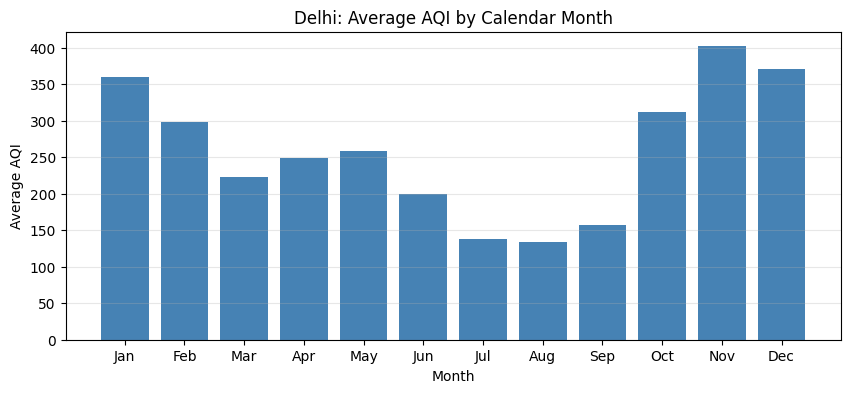

In [ ]:
monthly_aqi = aqi.groupby(aqi.index.month).mean()

plt.figure(figsize=(10, 4))
plt.bar(
    range(1, 13),
    monthly_aqi.reindex(range(1, 13)),
    color="steelblue"
)
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.title("Delhi: Average AQI by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
print("Start date:", aqi.index.min().date())
print("End date:", aqi.index.max().date())

Start date: 2015-01-01
End date: 2020-07-01


In [ ]:
print(results.round(2))

            MAE   RMSE
Model                 
Baseline  29.63  41.06
ARIMA     24.99  32.77
SARIMA    24.90  32.76
